In [5]:
# ◇━━━━━━━━━━━━  BORDER-DETECTION with ADAPTIVE DARK-PIXEL MASK  ━━━━━━━━━━━◇
# Loads one PDF page, detects the page frame via inward probes, and shows:
#   • probe hits  (blue)     • fitted border lines (green)
#   • RANSAC corner pts (red)• warped, rectified page
#   • binary mask of “dark / black” pixels (white)
#
# If any edge gets < 10 probe hits, thresholds are relaxed once (+20 on V & S).

import cv2
import fitz
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import random
import os
import time
import json
from collections import defaultdict

# ═════════════════════  helper: adaptive probe homography  ════════════════
def find_border_homography(page,
                           dpi             = 150,
                           max_search_frac = 0.15,
                           probes          = 25,
                           min_probes      = 10, # otherwise, SV adjust
                           min_inliers     = 10, # otherwise, also include outliers
                           v_thresh_init   = 128,
                           s_thresh_init   = 128,
                           tolerance       = 5.0,
                           ncheckwin       = ((-1, 2), (-1, 2)),
                           dilationwin     = (3, 3),
                           y_band_px       = 10,
                           min_cluster_pts = 10):
    """
    Returns:
      Hmat (3×3 homography),
      (w_out, h_out) target canvas,
      border_pts dict, lines dict, corners tuple, border_mask (bool array)
    """
    (rmin, rmax), (cmin, cmax) = ncheckwin

    # ── render RGB and convert to HSV ───────────────────────────────
    pix = page.get_pixmap(dpi=dpi, colorspace=fitz.csRGB, alpha=False)
    rgb = np.frombuffer(pix.samples, np.uint8).reshape(pix.height, pix.width, 3)
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    Hpx, Wpx = hsv.shape[:2]

    # ── collect probe points along dark pixel edges and return endpoints ─────────────────
    def collect_edges(v_thr, s_thr):
        mask = (hsv[..., 2] < v_thr) & (hsv[..., 1] < s_thr)
        mask = cv2.dilate(mask.astype(np.uint8), np.ones(dilationwin, np.uint8)) > 0
        
        # Store march endpoint coordinates
        bp = {"L": [], "R": [], "T": [], "B": []}

        # march to limit, with given directional step vectors
        def march(start, step, limit):
            r, c = start
            for _ in range(limit):
                if np.any(mask[r + rmin:r + rmax, c + cmin:c + cmax]):
                    return c if step[1] else r
                r += step[0]
                c += step[1]
            return None

        # march start points
        rows = np.linspace(int(.05 * Hpx), int(.95 * Hpx), probes, dtype=int)
        cols = np.linspace(int(.05 * Wpx), int(.95 * Wpx), probes, dtype=int)
        
        # pixel borders for 15%
        max_dx = int(max_search_frac * Wpx)
        max_dy = int(max_search_frac * Hpx)

        # utilize direction step vectors
        for r in rows:
            xL = march((r, 0),       (0,  1), max_dx)
            if xL is not None: 
                bp["L"].append([xL, r])
            xR = march((r, Wpx - 1), (0, -1), max_dx)
            if xR is not None: 
                bp["R"].append([xR, r])
        for c in cols:
            yT = march((0, c),       (1, 0),  max_dy)
            if yT is not None: 
                bp["T"].append([c, yT])
            yB = march((Hpx - 1, c), (-1, 0), max_dy)
            if yB is not None: 
                bp["B"].append([c, yB])
        return bp, mask

    border_pts, border_mask = collect_edges(v_thresh_init, s_thresh_init)

    # Try again if less than certain amount of probe points (min_probes) reliable for lsrl
    if any(len(pts) < min_probes for pts in border_pts.values()):
        border_pts, border_mask = collect_edges(v_thresh_init + 20, s_thresh_init + 20)
        if any(len(pts) < min_probes for pts in border_pts.values()):
            raise RuntimeError("Border detection failed: insufficient probe hits.")

    # ── Outlier bucket to avoid dict-resize error ───────────────────
    border_pts['OUT'] = []

    # ── Top-cluster extraction for "B" (bottom) only ────────────────
    def extract_top_cluster(points):
        buckets = defaultdict(list)
        for x, y in points:
            band = int(y // y_band_px)
            buckets[band].append((x, y))
        for band in sorted(buckets.keys()):
            if len(buckets[band]) >= min_cluster_pts: # min amount of points to count as significant cluster for lsrl
                return np.array(buckets[band], np.float32)
        return np.array(points, np.float32)
    
    # ── Bottom-cluster extraction for "T" (bottom) only ────────────────
    def extract_bottom_cluster(points):
        buckets = defaultdict(list)
        for x, y in points:
            band = int(y // y_band_px)
            buckets[band].append((x, y))
        for band in sorted(buckets.keys(), reverse=True):
            if len(buckets[band]) >= min_cluster_pts: # min amount of points to count as significant cluster for lsrl
                return np.array(buckets[band], np.float32)
        return np.array(points, np.float32)

    # ── Line fitting and filtering per edge ─────────────────────────
    lines = {}
    for side in ["T", "B", "L", "R"]:
        
        ## Load points
        pts = border_pts[side] # list of coords

        # Bottom side requires special processing due to existence of footers
        if side == "B":
            # Add potential outliers to allow fallback
            pts += border_pts["OUT"]
            pts = extract_top_cluster(pts)

        # Top side requires special processing due to existence of header notes
        if side == "T":
            # Add potential outliers to allow fallback
            pts += border_pts["OUT"]
            pts = extract_bottom_cluster(pts)

        pts = np.asarray(pts, np.float32)

        if pts.shape[0] < 2:
            raise RuntimeError(f"Too few points on edge {side}")
        
        ## Capture line equation
        vx, vy, x0, y0 = cv2.fitLine(pts, cv2.DIST_L2, 0, 0.01, 0.01)
        
        # Distance calculation for outliers
        A, B = vy, -vx # norms
        C = -(A * x0 + B * y0) # intercept Ax+By+C=0
        dist = np.abs(A * pts[:, 0] + B * pts[:, 1] + C) / np.hypot(A, B)
        inliers = pts[dist < tolerance]
        outliers = pts[dist >= tolerance]
        border_pts['OUT'].extend(outliers.tolist()) # add outliers

        # Fit only inliers if sufficient quantity of inliers
        if len(inliers) >= min_inliers:
            vx, vy, x0, y0 = cv2.fitLine(inliers, cv2.DIST_L2, 0, 0.01, 0.01)
            A, B = vy, -vx
            C = -(A * x0 + B * y0)
            border_pts[side] = inliers.tolist()

        lines[side] = (A, B, C)

    # ── Intersect the lines ─────────────────────────
    def intersect(L1, L2):
        A1, B1, C1 = L1
        A2, B2, C2 = L2
        D = A1 * B2 - A2 * B1
        return [(B1 * C2 - B2 * C1) / D, (C1 * A2 - C2 * A1) / D]

    tl = intersect(lines["T"], lines["L"])
    tr = intersect(lines["T"], lines["R"])
    br = intersect(lines["B"], lines["R"])
    bl = intersect(lines["B"], lines["L"])

    # Intersections
    dst = np.array([tl, tr, br, bl], np.float32) # location of intersections
    w_out = int(np.linalg.norm(np.subtract(tr, tl)))
    h_out = int(np.linalg.norm(np.subtract(bl, tl)))
    src = np.array([[0, 0], [w_out, 0], [w_out, h_out], [0, h_out]], np.float32) # normalized

    Hmat, _ = cv2.findHomography(dst, src, 0)
    return Hmat, (w_out, h_out), border_pts, lines, (tl, tr, br, bl), border_mask


Total time take: 0.09855358302593231


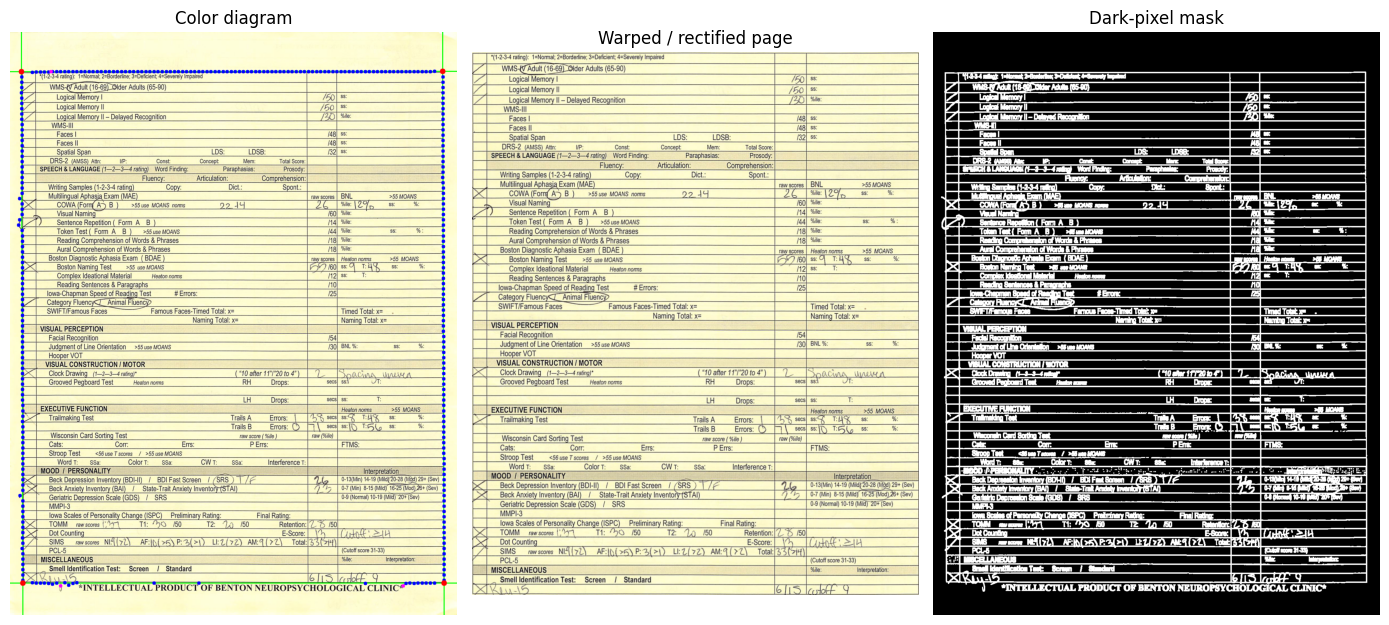

'\n2018 ~ rosenbaum\n'

In [6]:
# ───── user paths & params ────────────────────────────────────────────────
sheets_dir = '../case_outputs/sheets'
seg_dir = '../case_outputs/seg'
scan_pdf   = Path(os.path.join(sheets_dir, random.choice(os.listdir(sheets_dir))))   # scanned PDF
page_idx   = 1                                          # page number (0-based)
dpi_render = 150                                        # render dpi
probes     = 100                                         # probes per edge
tolerance  = 15                                         # max perpendicular distance threshold for outlier
ncheckwin  = ((-1, 2), (0, 1))                         # Area around probe point to be checked for dark pixels
dilationwin = (3, 3)                                    # Kernel size for dilating the darkmap
# ──────────────────────────────────────────────────────────────────────────

# ---------- load page → BGR numpy ----------------------------------------
doc  = fitz.open(scan_pdf)
page = doc[page_idx]

pix  = page.get_pixmap(dpi=dpi_render, colorspace=fitz.csRGB, alpha=False)
img_rgb = np.frombuffer(pix.samples, np.uint8).reshape(pix.height, pix.width, 3)
img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)

# ═══════════ compute homography, warp, and draw diagnostics  ════════════

t0 = time.perf_counter()
Hmat, (W_out, H_out), border_pts, lines, corners, border_mask = \
    find_border_homography(
        page, dpi=dpi_render, probes=probes, v_thresh_init=200, s_thresh_init=128,
        tolerance=tolerance, ncheckwin=ncheckwin, dilationwin=dilationwin
    )
homography_time = time.perf_counter()-t0
print(f"Total time take: {homography_time}")

pix_aligned = cv2.warpPerspective(img_bgr, Hmat, (W_out, H_out))

# ---- diagnostic canvas --------------------------------------------------
vis = img_bgr.copy()

def draw_ABCl(A, B, C, col):
    A = A.item()
    B = B.item()
    C = C.item()
    h, w = vis.shape[:2]
    if abs(B) > abs(A):                               # ≈ horizontal line
        x1, y1 = 0, int(-C / B)
        x2, y2 = w, int((-A * w - C) / B)
    else:                                             # ≈ vertical line
        x1, y1 = int(-C / A), 0
        x2, y2 = int((-B * h - C) / A), h
    cv2.line(vis, (x1, y1), (x2, y2), col, 2)

# draw border lines first (green)
for coeff in lines.values():
    draw_ABCl(*coeff, (0, 255, 0))

# draw probe hits (blue)
for pts in border_pts.values():
    if pts is border_pts['OUT']:
        continue            # handled below
    for x, y in pts:
        cv2.circle(vis, (int(x), int(y)), 5, (255, 0, 0), -1)   # blue

# draw outlier hits last (pink)
for x, y in border_pts['OUT']:
    cv2.circle(vis, (int(x), int(y)), 5, (255, 0, 255), -1)     # yellow

# draw corner intersections last (red)
for x, y in corners:
    cv2.circle(vis, (int(x.item()), int(y.item())), 8, (0, 0, 255), -1)

# ---- show results -------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(14, 10))

axes[0].set_title("Color diagram")
axes[0].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
axes[0].axis('off')

axes[1].set_title("Warped / rectified page")
axes[1].imshow(cv2.cvtColor(pix_aligned, cv2.COLOR_BGR2RGB))
axes[1].axis('off')

axes[2].set_title("Dark-pixel mask")
axes[2].imshow(border_mask.astype(np.uint8) * 255, cmap='gray')
axes[2].axis('off')

plt.tight_layout()

plt.show()



"""
2018 ~ rosenbaum
"""

In [7]:
with open('../templates/spring2025.json') as f:
    format = json.load(f)

segments = format['sections']

for seg_title, seg_coords in segments.items():
    page_no, p0, q0, p1, q1 = seg_coords
    h, w, _ = pix_aligned.shape
    x0, y0, x1, y1 = int(w * p0), int(h * q0), int(w * p1), int(h * q1)
    cv2.imwrite(
        os.path.join(seg_dir, f"{seg_title}_{scan_pdf.stem}.png"),
        cv2.cvtColor(pix_aligned[y0 : y1+1, x0: x1+1], cv2.COLOR_BGR2RGB)
    )
    